# prePilot Drone task analysis

This report checks the saved observations before describing tracking and the three memory responses. It reads canonical raw sessions by default. A cumulative checkpoint and its final export are one session. Older recordings remain visible in the inventory and are excluded from the current protocol summaries.

The figures compare blocks and response types within a selected session. Trials, memory pairs, and mouse movements are repeated observations from that session. A single current pilot cannot establish population effects, screening validity, or readiness for recruitment.

## Configuration and intake

Run all cells after adding exports to `analysis/data/prePilot/drone_task/raw`. The shared loader also discovers optional module raw folders. It checks snapshot overlap, preserves recorded identifiers as strings, and never rewrites the raw or existing clean files.

Set `DRONE_INPUT_MODE=clean` and `DRONE_CLEAN_DIR` only when deliberately analyzing an existing split collection. The default report requires current schema data. `DRONE_DERIVED_DIR` can redirect exports to an isolated audit directory. The focus session can be selected with the safe ordinal label in `DRONE_FOCUS_SESSION`.

In [1]:
import os, sys, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'index.html').exists() and (p / 'analysis').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from within the DroneTask repository.')
sys.path.insert(0, str(ROOT / 'analysis'))
sys.path.insert(0, str(ROOT / 'analysis/drone_task'))
from session_io import load_module_tables
import drone_analysis as analysis

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlepad': 12,
                     'axes.grid': True, 'grid.alpha': .18, 'savefig.facecolor': 'white'})
pd.set_option('display.max_columns', 14)
clean_override = os.environ.get('DRONE_CLEAN_DIR')
INPUT_MODE = os.environ.get('DRONE_INPUT_MODE', 'clean' if clean_override else 'raw')
DERIVED = Path(os.environ.get('DRONE_DERIVED_DIR', ROOT / 'analysis/data/prePilot/drone_task/derived'))
FIGURES = DERIVED / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
bundle = load_module_tables('drone_task', root=ROOT, input_mode=INPUT_MODE, clean_dir=clean_override if INPUT_MODE == 'clean' else None)
inventory = bundle['inventory']
if inventory.empty:
    raise RuntimeError('No sessions found. Add the saved raw CSV export and run all cells again.')
issues = bundle['issues']
if len(issues) and issues.severity.eq('error').any():
    display(issues.groupby(['severity', 'check']).size().rename('count').reset_index())
    raise RuntimeError('Resolve intake errors before interpreting the analysis. Details remain in bundle["issues"].')

# Identify sessions that actually include the main task. Standalone screening
# or mouse checks have zero main trials by design and are not failed main runs.
encoding_ids = set(bundle['tables']['encoding'].get('session_id', []))
main_eligible = inventory.session_id.isin(encoding_ids) | analysis.numeric(inventory, 'expected_main_encoding').gt(0)
current = inventory.loc[main_eligible & inventory.source_schema.eq('current')].copy()
if current.empty:
    raise RuntimeError('No current main task session found. Legacy recordings are intentionally not pooled with the current protocol.')
current_ids = set(current.session_id)
tables = analysis.prepare_tables(bundle['tables'], current_ids)
enc, mem = tables['encoding'], tables['memory']
focus_label = os.environ.get('DRONE_FOCUS_SESSION', current.session_label.iloc[-1])
if focus_label not in set(current.session_label):
    raise ValueError('DRONE_FOCUS_SESSION must be a current main task session_label from the inventory.')
focus_info = current.loc[current.session_label.eq(focus_label)].iloc[0]
focus_tables = analysis.prepare_tables(bundle['tables'], {focus_info.session_id})
focus_enc, focus_mem = focus_tables['encoding'], focus_tables['memory']
summary = analysis.block_summary(enc, mem)
focus_summary = summary.loc[summary.session_id.eq(focus_info.session_id)].sort_values('block')
checks = analysis.recording_checks(tables, current)

safe_inventory = inventory[['session_label', 'source_schema', 'task_version', 'source_kind',
                            'source_row_count', 'snapshot_count', 'outcome']].copy()
display(safe_inventory.rename(columns={'source_row_count': 'selected_rows'}))
display(Markdown(f'**{len(current)} current main task session.** Figures show {focus_label}. '
                 f'{len(inventory) - len(current)} other session records remain outside this report cohort.'))
if len(issues):
    display(issues.groupby(['severity', 'check']).size().rename('count').reset_index())

,session_label,source_schema,task_version,source_kind,selected_rows,snapshot_count,outcome
0,Session 001,legacy,v3.1-png-main-practice-emoji-latin-square-bloc...,raw,312,1,NaN
1,Session 002,legacy,v3.1-png-main-practice-emoji-latin-square-bloc...,raw,308,1,NaN
2,Session 003,current,v3.14.0-acknowledged-data-saving,final,734,2,completed


**1 current main task session.** Figures show Session 003. 2 other session records remain outside this report cohort.

## Recording completeness and telemetry

The full protocol requires 200 unique encoding turns and four complete sequences from turn 1 to 50, together with 56 unique memory pair summaries and 14 pairs in each block. Route specific expected counts are read from the saved manifest. A saved pair can still contain an unanswered stage. These checks verify content structure and arithmetic rather than cloud delivery acknowledgement or participant eligibility.

Missing display outcomes are explicitly unrecorded. They do not prove that an item failed to appear or that it rendered successfully. Earlier runtime versions had a display logging scope bug; repaired versions record load route, load and decode results, fallback reason, and visible timing separately. Historical missing values are never filled from the repaired implementation. Preload counters are reported as recorded. In background mode, preload elapsed time is not the time a participant waited at a blocking screen.

In [2]:
display(checks.drop(columns='session_label') if len(current) == 1 else checks)
metadata = tables['metadata']
telemetry_columns = ['session_label', 'preload_loaded', 'preload_total', 'preload_failed',
                     'preload_mode', 'preload_elapsed_ms', 'preload_overall_timeout']
display(metadata.reindex(columns=telemetry_columns))
coverage = []
for _, info in current.iterrows():
    sid = info.session_id
    row = {'session_label': info.session_label}
    for name in ['encoding', 'memory', 'demographics', 'memory_screening_encoding',
                 'memory_screening_order', 'mouse_trajectory']:
        frame = tables[name]
        row[name] = int(frame.session_id.eq(sid).sum()) if 'session_id' in frame else 0
    coverage.append(row)
display(pd.DataFrame(coverage))
failed_checks = checks.loc[checks.status.eq('fail')]
if len(failed_checks):
    display(Markdown('**Content checks failed.** Inspect the rows above before interpreting behavioral summaries.'))

,check,status,observed,expected
0,Encoding rows,pass,200,200.0
1,Memory pair summaries,pass,56,56.0
2,Complete encoding blocks,pass,4,4.0
3,Complete memory blocks,pass,4,4.0
4,Finite positions within the rail,pass,1,1.0
5,Scoring agrees with pieces caught,pass,200,200.0
6,Memory gap agrees with item indices,pass,56,56.0
7,Recorded placement targets agree with indices,pass,54,54.0
8,Order correctness agrees with selected image,pass,56,56.0
9,Memory images agree with studied item indices,pass,56,56.0


,session_label,preload_loaded,preload_total,preload_failed,preload_mode,preload_elapsed_ms,preload_overall_timeout
2,Session 003,200,200,1,background,398854,False


,session_label,encoding,memory,demographics,memory_screening_encoding,memory_screening_order,mouse_trajectory
0,Session 003,200,56,1,20,10,8


## Recorded task and condition mapping

The block number is presentation order. Saved nominal condition labels are joined from the encoding observations using session and displayed block, rather than inferred from block number or a file name. High volatility is paired with low stochasticity, and low volatility with high stochasticity. Their effects cannot be separated as independent factors in this design.

All positions use percent of the rail. The hidden drone trace is an analysis reference that participants could not see during the main game. Recorded supply positions and the collector are shown on the same scale. The recorded supply position determines scoring. Earlier runtime versions clamped the visual supply center to 12 through 88 percent, so two positions near the left edge in the historical pilot differ from their displayed centers. Repaired runtime versions use the same landing coordinate for rendering and scoring and retain both positions explicitly. Historical missing render telemetry is not replaced with new measurements; these plots retain each session’s recorded supply positions.

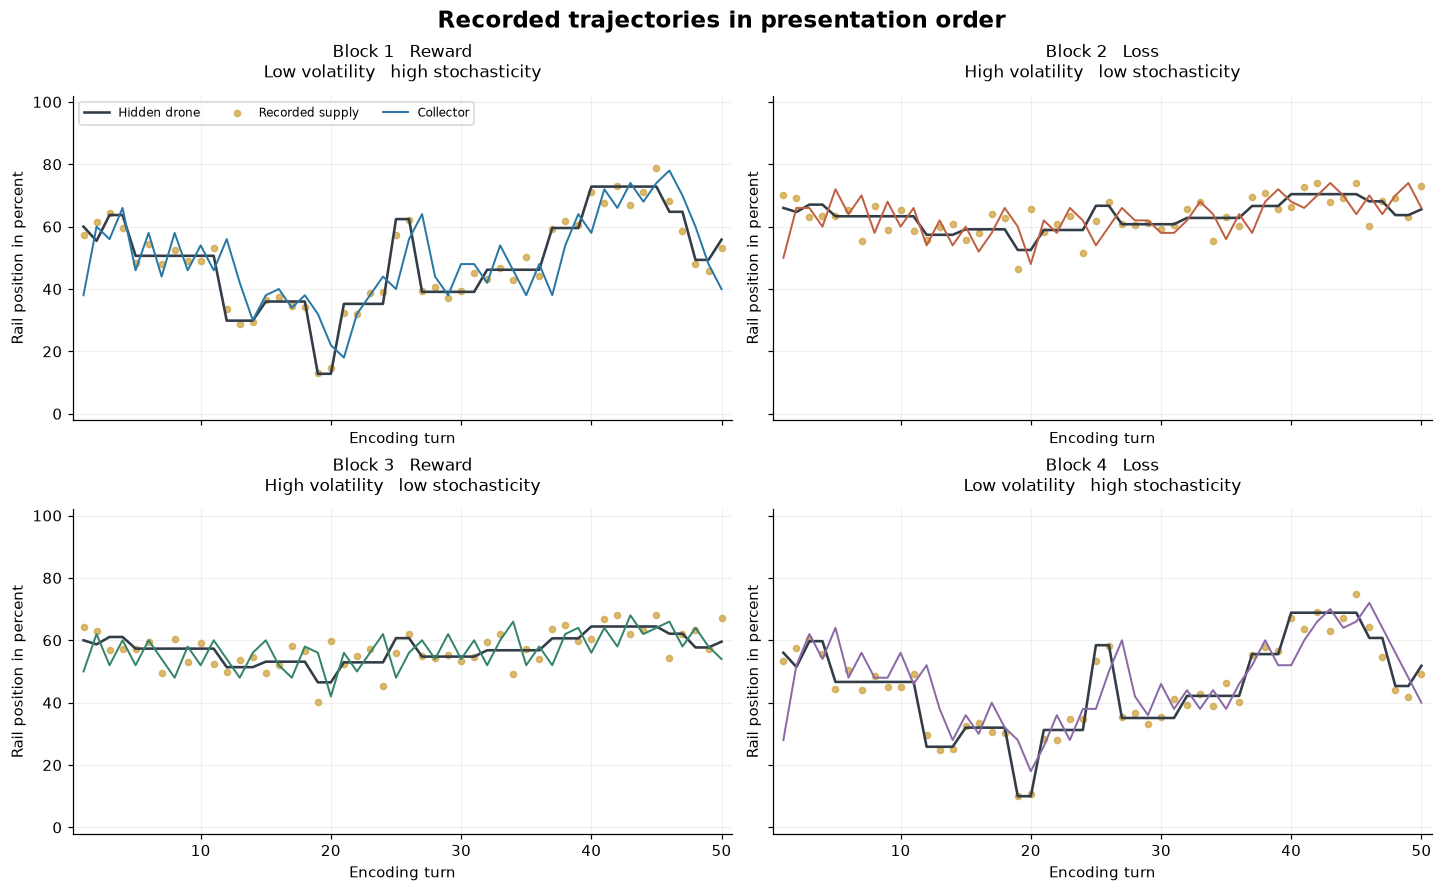

,block,condition_id,encoding_rows,memory_pairs,mean_abs_target_step_pp,mean_abs_wind_offset_pp
0,1.0,B_reward_lowVol_highStc,50,14,4.340,2.508
1,2.0,C_loss_highVol_lowStc,50,14,1.225,3.388
2,3.0,A_reward_highVol_lowStc,50,14,1.225,3.388
3,4.0,D_loss_lowVol_highStc,50,14,4.292,2.481


In [3]:
if len(focus_enc):
    fig = analysis.plot_tracking(focus_enc, focus_summary)
    analysis.export_figure(fig, FIGURES / '01_recorded_trajectories.png')
    plt.show()
else:
    display(Markdown('No main encoding observations are available for the selected session.'))
display(focus_summary[['block', 'condition_id', 'encoding_rows', 'memory_pairs',
                       'mean_abs_target_step_pp', 'mean_abs_wind_offset_pp']].round(3))

## Recorded labels and realized geometry

**Historical v14 condition names disagree with their recorded movement ordering.** In those recordings, nominal high volatility blocks have smaller drone shifts and nominal high stochasticity blocks have smaller supply distances than their low labelled counterparts. The historical pilot shown in this report retains those recorded labels.

From `condition_label_version=trajectory-aligned-v2-20261104` with stimuli v15, the runtime high and low labels match realized ordering without changing the trajectories, canonical indices, valence or boundary positions. Numeric factor values remain nominal design codes rather than estimates of empirical variance. Historical data are never retroactively relabelled.

The figure separates all transitions from transitions where the drone actually moved. Check the recorded label version and realized geometry before interpreting a contrast. Corrected and historical label versions do not denote equivalent named conditions.

,nominal_factor,metric,saved_high_mean_pp,saved_low_mean_pp,ordering
0,vol_level,Movement size when the drone changes position,4.00060,14.099333,inverted
1,stc_level,Absolute supply landing distance from the drone,2.49459,3.387520,inverted


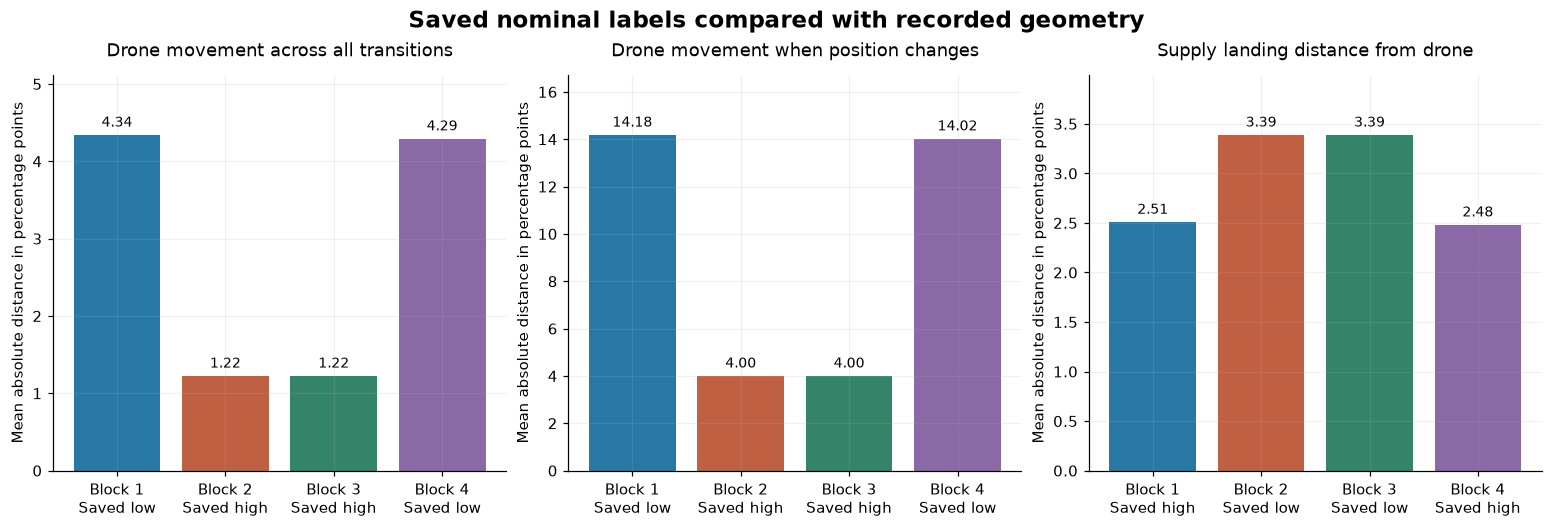

In [4]:
condition_checks = analysis.manipulation_checks(summary)
display(condition_checks.drop(columns='session_label') if len(current) == 1 else condition_checks)
if len(focus_summary):
    fig = analysis.plot_manipulations(focus_summary)
    analysis.export_figure(fig, FIGURES / '07_nominal_labels_and_realized_geometry.png')
    plt.show()

## Tracking and updating

Pieces caught are comparable across reward and loss blocks. Scores have different signs because a reward turn gives one point per caught piece and a loss turn gives minus one point per missed piece. Collector error relative to the hidden drone measures tracking; error relative to the actual landing includes supply variation.

The descriptive update slope regresses the next collector position change on the current signed landing error, with an intercept. It uses consecutive turns within the same block only. It is not a model recovered learning rate. There are no participant error bars or significance tests based on repeated turns.

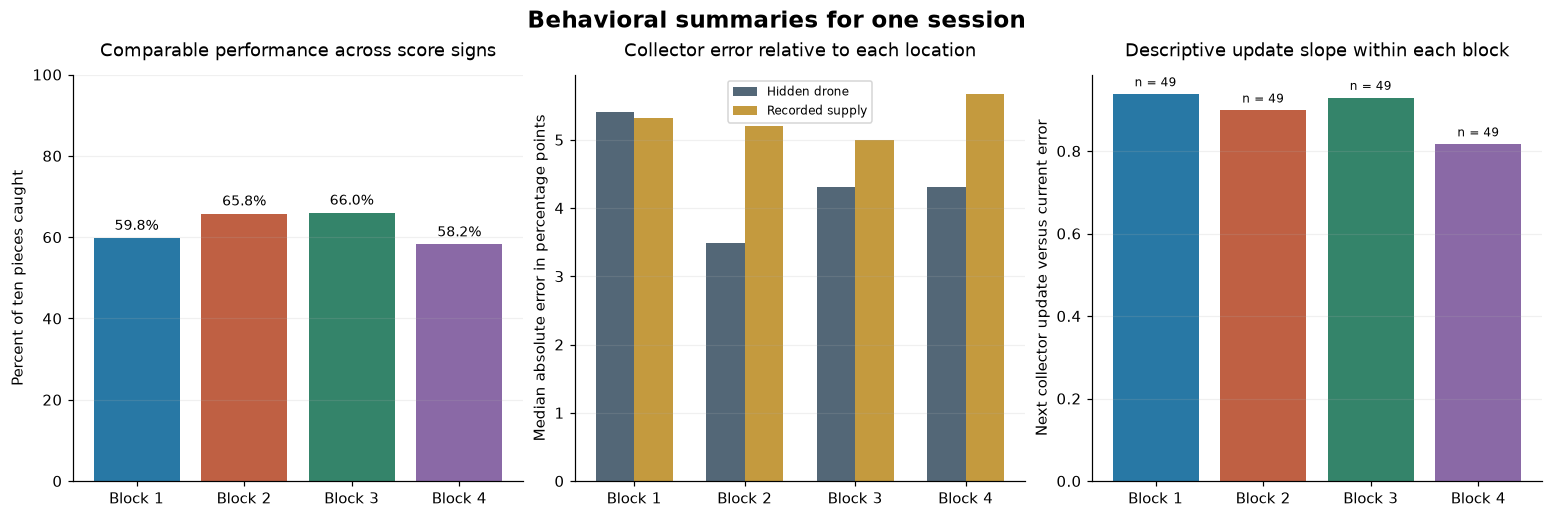

,block,caught_fraction,score,median_target_error_pp,median_landing_error_pp,stayed_fraction,update_slope,update_transitions,update_slope_status
0,1.0,0.598,299.0,5.402,5.315,0.02,0.938,49,estimated
1,2.0,0.658,-171.0,3.485,5.195,0.06,0.899,49,estimated
2,3.0,0.660,330.0,4.313,5.003,0.02,0.930,49,estimated
3,4.0,0.582,-209.0,4.307,5.672,0.06,0.817,49,estimated


In [5]:
if len(focus_summary):
    fig = analysis.plot_behavior(focus_enc, focus_summary)
    analysis.export_figure(fig, FIGURES / '02_tracking_and_updating.png')
    plt.show()
display(focus_summary[['block', 'caught_fraction', 'score', 'median_target_error_pp',
                       'median_landing_error_pp', 'stayed_fraction', 'update_slope',
                       'update_transitions', 'update_slope_status']].round(3))

## Memory outcomes and units

Order accuracy uses answered questions as its primary denominator. Accuracy across all recorded pair summaries is exported separately so omissions can be counted as unsuccessful when that is the planned estimand. The dotted 50 percent line is a two choice reference, not evidence of a population effect.

The current distance response is a subjective slider from 0 to 100 with endpoints Very close and Very far. It is not a count of intervening items. Ratings are therefore compared between the actual separations of one and two intervening items; subtracting those counts from the slider would mix incompatible units. Older files used a different response range and are not pooled here.

Placement has a measurable target. Its true percent position is 100 × (probe index − first reference index) / (second reference index − first reference index). Absolute placement error is measured in percentage points. Omitted placements are excluded from accuracy summaries and retained in missingness counts.

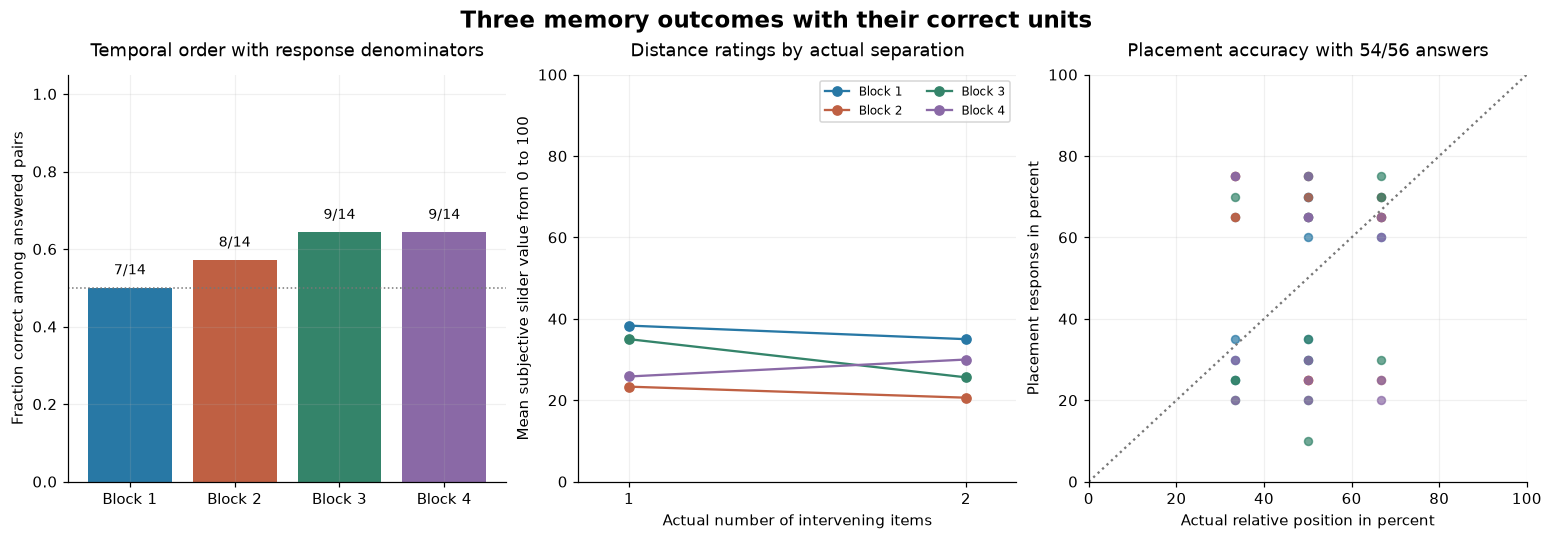

,block,order_correct,order_answered,order_accuracy_answered,order_accuracy_all_recorded_pairs,distance_answered,placement_answered,placement_mae_pp
0,1.0,7.0,14,0.500,0.500,14,13,12.051
1,2.0,8.0,14,0.571,0.571,14,14,23.571
2,3.0,9.0,14,0.643,0.643,14,13,20.000
3,4.0,9.0,14,0.643,0.643,14,14,23.333


In [6]:
if len(focus_mem):
    fig = analysis.plot_memory(focus_mem, focus_summary)
    analysis.export_figure(fig, FIGURES / '03_memory_outcomes.png')
    plt.show()
display(focus_summary[['block', 'order_correct', 'order_answered', 'order_accuracy_answered',
                       'order_accuracy_all_recorded_pairs', 'distance_answered', 'placement_answered',
                       'placement_mae_pp']].round(3))

## Attempts and final missingness

Each recorded attempt is retained. A timeout followed by a valid retry differs from a final omission. The pair summary determines whether the final stage was answered; the attempt events describe how that answer was reached. No pair is dropped because an earlier attempt timed out.

First interaction latency subtracts the recorded asset visibility offset from the stage construction clock. Slider completion time begins at the first interaction. The 5 second and 7 second lines reproduce the participant timing notices; recorded timeout flags remain authoritative because event delivery can be slightly delayed. Unavailable timing remains unavailable.

,stage,recorded_pairs,intended_pairs,missing_pair_summaries,final_answered,final_unanswered,recorded_attempts,timeout_attempts,timeout_flag_missing,timing_available
0,order,56,56,0,56,0,58,2,0,True
1,distance,56,56,0,56,0,57,1,0,True
2,placement,56,56,0,54,2,56,2,0,True


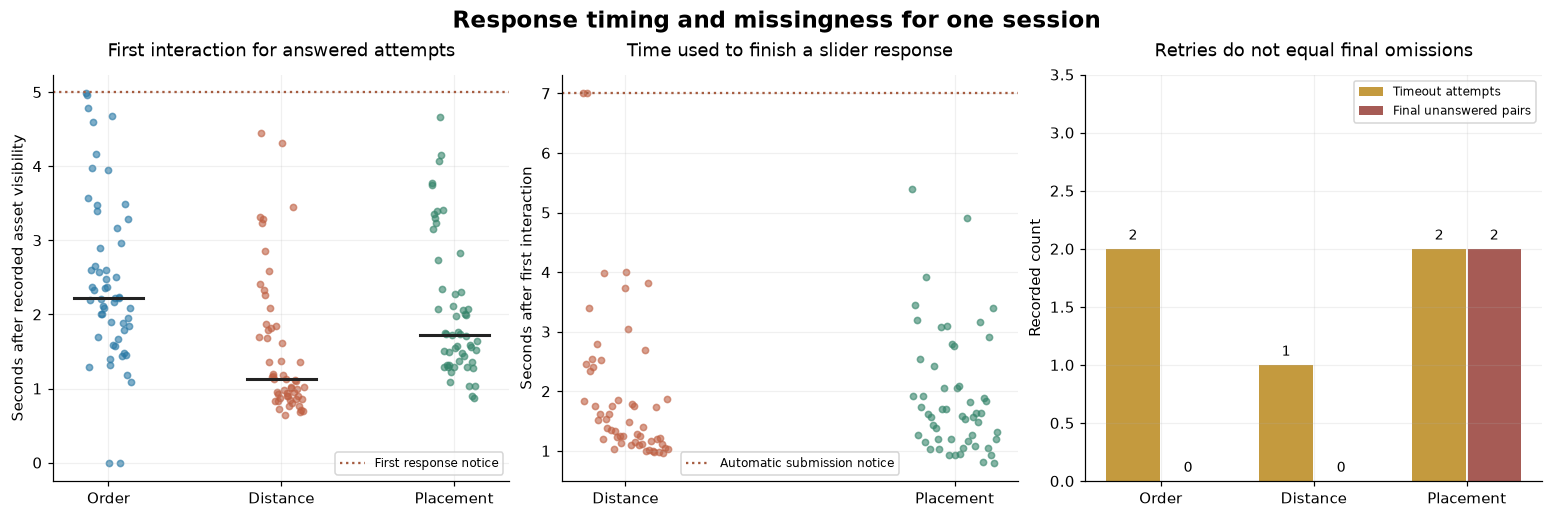

In [7]:
events = focus_tables['response_events']
intended_pairs = pd.to_numeric(focus_info.get('expected_main_memory_pairs'), errors='coerce')
stages = analysis.stage_summary(focus_mem, events, intended_pairs=int(intended_pairs) if pd.notna(intended_pairs) else None)
display(stages)
if len(events):
    fig = analysis.plot_response_timing(events, stages)
    analysis.export_figure(fig, FIGURES / '04_response_timing_and_omissions.png')
    plt.show()
else:
    display(Markdown('Attempt level response timing was not recorded for this session.'))

## Pair design and segmentation support

A hidden position change is counted only when it occurs between the two tested item onsets. The recorded memory indices and encoding turns are both one based. A missing intervening observation makes span coverage unavailable rather than a no change interval.

The figure displays support before estimating any boundary contrast. Zero cells cannot support within block comparisons. Separation and block condition can differ in their exposure to hidden changes. This report does not interpret an unmatched difference as a segmentation effect. The former post hoc error threshold, significance based pilot gates, effect size extrapolation, and Kalman parameter recovery plot have been removed. The old observational fit did not establish identification or parameter recovery.

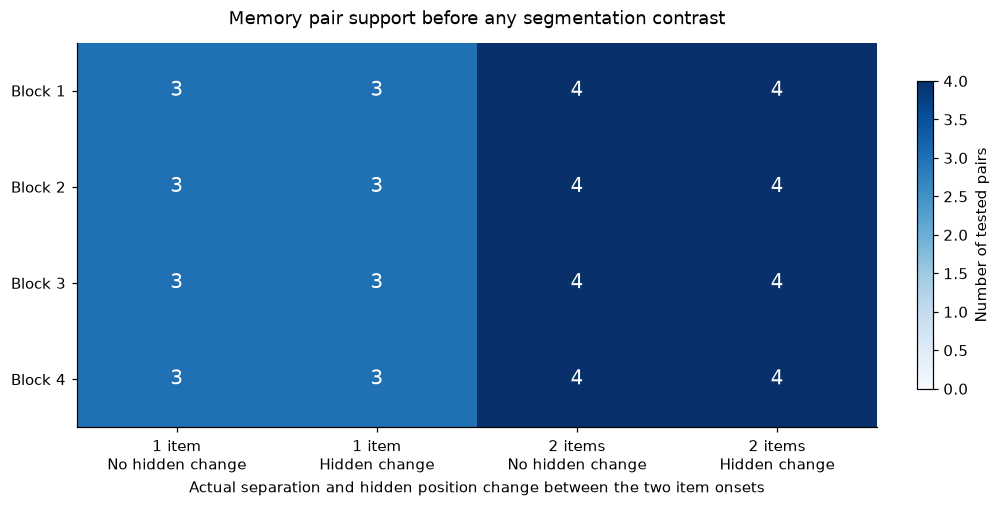

,block,true_gap,crosses_hidden_change,n_pairs,n_order,n_distance,n_placement
0,1.0,1.0,False,3,3,3,3
1,1.0,1.0,True,3,3,3,3
2,1.0,2.0,False,4,4,4,4
3,1.0,2.0,True,4,4,4,3
4,2.0,1.0,False,3,3,3,3
5,2.0,1.0,True,3,3,3,3
6,2.0,2.0,False,4,4,4,4
7,2.0,2.0,True,4,4,4,4
8,3.0,1.0,False,3,3,3,3
9,3.0,1.0,True,3,3,3,3


In [8]:
support = analysis.pair_support(focus_mem) if len(focus_mem) else pd.DataFrame()
if len(support):
    fig = analysis.plot_pair_support(support, focus_summary)
    analysis.export_figure(fig, FIGURES / '05_memory_pair_support.png')
    plt.show()
    display(support[['block', 'true_gap', 'crosses_hidden_change', 'n_pairs', 'n_order', 'n_distance', 'n_placement']])

## Comprehension and instruction review

Submission attempts show whether a correction followed review and whether the final submission was correct. Instruction page visits come from the expanded `view_history` records. Page view events in the event ledger are not added again, which would double count the same visit. Durations describe engagement rather than validated attention or eligibility.

,session_label,attempt,questions,correct,errors,completed,review_topic
0,Session 003,1.0,12,11,1.0,False,inst3
1,Session 003,2.0,12,12,0.0,True,NaN


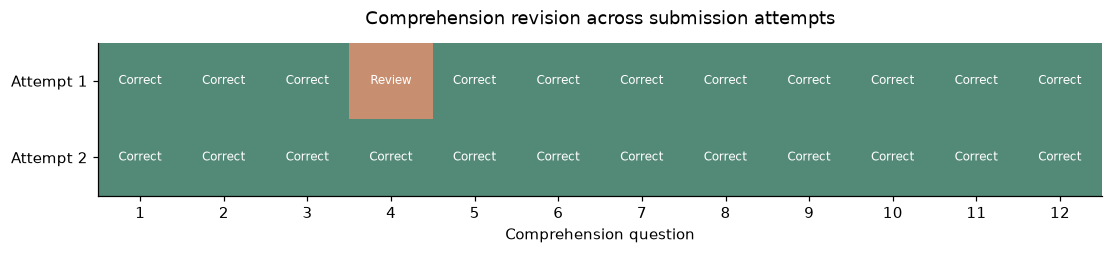

,page_visits,distinct_recorded_pages,total_viewing_seconds,visits_with_missing_duration
0,33,29,214.81,0


In [9]:
comprehension = focus_tables['comprehension'].sort_values('trial_index')
comp_summary = analysis.comprehension_summary(comprehension)
display(comp_summary)
if len(comprehension) and comprehension.correctness_responses.notna().any():
    fig = analysis.plot_comprehension(comprehension)
    analysis.export_figure(fig, FIGURES / '06_comprehension_review.png')
    plt.show()
views = focus_tables['instruction_views']
if len(views):
    durations = analysis.numeric(views, 'viewing_time')
    display(pd.DataFrame([{'page_visits': len(views),
                           'distinct_recorded_pages': views.viewed_screen_id.nunique() if 'viewed_screen_id' in views else np.nan,
                           'total_viewing_seconds': durations.sum(min_count=1) / 1000,
                           'visits_with_missing_duration': int(durations.isna().sum())}]).round(2))

## Audit exports and interpretation

Derived tables retain stable internal session identifiers for private joins. Saved notebook outputs and figures show ordinal session labels only. These labels can change when more files are added and are not persistent identifiers. Raw recordings and existing split collections remain unchanged.

The exports include the full cohort block summaries, final memory outcomes, attempt events, integrity checks, and pair support. The analysis manifest records selected source hashes and analysis code hashes. Outputs belong in the ignored `analysis/data/prePilot/drone_task/derived` directory, with PNG figures in its `figures` subfolder.

The report establishes what was recorded and identifies missing telemetry or unanswered responses. Interpretation of condition effects, exclusion rules, model parameters, and screening benefit requires a planned analysis and additional independent participants.

In [10]:
checks.to_csv(DERIVED / 'recording_checks.csv', index=False)
summary.to_csv(DERIVED / 'block_summary.csv', index=False)
mem.to_csv(DERIVED / 'memory_outcomes.csv', index=False)
tables['response_events'].to_csv(DERIVED / 'response_attempts.csv', index=False)
stages.to_csv(DERIVED / 'focus_response_summary.csv', index=False)
support.to_csv(DERIVED / 'focus_pair_support.csv', index=False)
comp_summary.to_csv(DERIVED / 'focus_comprehension.csv', index=False)
safe_inventory.to_csv(DERIVED / 'session_inventory.csv', index=False)
source_hashes = current.get('source_sha256', pd.Series(dtype=str)).dropna().tolist()
code_paths = ['analysis/session_io.py', 'analysis/split_drone_data.py',
              'analysis/drone_task/drone_analysis.py']
condition_checks.to_csv(DERIVED / 'condition_geometry_checks.csv', index=False)
manifest = {'input_mode': INPUT_MODE, 'current_main_sessions': len(current),
            'focus_session_label': focus_label, 'other_inventory_sessions': len(inventory)-len(current),
            'source_sha256': source_hashes,
            'code_sha256': {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in code_paths},
            'condition_geometry_ordering': condition_checks.ordering.tolist(),
            'recording_check_counts': checks.status.value_counts().to_dict(),
            'task_versions': sorted(current.task_version.dropna().unique().tolist()),
            'interpretation': 'descriptive session analysis without population inference'}
(DERIVED / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
result = pd.DataFrame([{'current_main_sessions': len(current),
                        'encoding_rows': len(enc), 'memory_pairs': len(mem),
                        'focus_order_correct': int(analysis.numeric(focus_mem, 'order_correct_bin').sum()),
                        'focus_order_answered': int(focus_mem.order_answered.sum()),
                        'focus_placement_answered': int(focus_mem.placement_answered.sum()),
                        'recording_failures': int(checks.status.eq('fail').sum()),
                        'unrecorded_diagnostics': int(checks.status.eq('not_recorded').sum())}])
display(result)
print('Exports written to the configured derived directory and its figures subfolder.')

,current_main_sessions,encoding_rows,memory_pairs,focus_order_correct,focus_order_answered,focus_placement_answered,recording_failures,unrecorded_diagnostics
0,1,200,56,33,56,54,0,1


Exports written to the configured derived directory and its figures subfolder.
